In [ ]:
import os
from tqdm import tqdm
from pathlib import Path
import anndata
import pandas as pd
from itertools import combinations
import seaborn as sns

from SCI_py.metrics.correlations import (
    create_reference_set, 
    compute_pairwise_correlations,
    compute_pairwise_stats
)
from SCI_py.plot.correlations import (
    # Diagnostics
    plot_masking_stats,
    plot_masking_heatmap,
    plot_missingness_distributions,
    plot_coobserved_diagnostic,
    # Correlations
    plot_intralab_correlation,
    plot_interlab_correlation_heatmap,
    plot_instrument_correlation,
    plot_sample_pair_correlations,
    plot_intralab_pairwise_stats
)

tqdm.pandas()

In [2]:
NOTEBOOK_DIR = Path().resolve()
ROOT_OUT      = NOTEBOOK_DIR / "../../Data"
ROOT_OUT      = ROOT_OUT.resolve()
ROOT_OUT.mkdir(parents=True, exist_ok=True)

# Allow user override via environment variable
ROOT_OUT = Path(os.environ.get("SCI_DATA_DIR", ROOT_OUT))

ROOT_OUT.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {ROOT_OUT}")

FIGURES_OUT = NOTEBOOK_DIR / "../../Figures"
FIGURES_OUT = FIGURES_OUT.resolve()
FIGURES_OUT.mkdir(parents=True, exist_ok=True)

# Overwrite with environment variable
FIGURES_OUT = Path(os.environ.get("SCI_FIGURES_DIR", FIGURES_OUT))
print(f"Figures directory: {FIGURES_OUT}")

ANNDATA_IN = os.path.join(
    ROOT_OUT,
    'AnnData',
    'out'
)

Output directory: /home/sam/SCI/SCI/Data
Figures directory: /home/sam/SCI/SCI/Figures


Load data from scplainer approach

In [7]:
adata_precursors = anndata.io.read_h5ad(
    os.path.join(
        ROOT_OUT,
        'scplainer',
        'SC',
        'precursor',
        'base',
        'scplainer_results.h5ad'
    )
)

# move varm from uns to actual varm
for key, mat in adata_precursors.uns['varm'].items():
    adata_precursors.varm[key] = mat
del adata_precursors.uns['varm']

# verify
print(adata_precursors)
print("\nobsm keys :", list(adata_precursors.obsm.keys()))
print("varm keys :", list(adata_precursors.varm.keys()))
print("uns keys  :", list(adata_precursors.uns.keys()))

print("\nDescription:")
print(adata_precursors.uns['scplainer_description'])

AnnData object with n_obs × n_vars = 1864 × 23037
    obs: 'sample_name', 'plate_id', 'plate_idx', 'source.name', 'comment.X.position.', 'comment.Y.position.', 'comment.Plate.Number.', 'comment.Gradient.time.', 'comment.thawing.timepoint.', 'comment.plate.arrival.', 'injection_order', 'institute_name', 'Reinjection', 'Diameter', 'Elongation', 'Circularity', 'Doublet', 'Dividing', 'Dying', 'CellInBlank', 'comment.plate.arrival._date', 'comment.plate.arrival._time', 'comment.plate.arrival._datetime', 'comment.Gradient.time._date', 'comment.Gradient.time._time', 'comment.Gradient.time._datetime', 'instrument_type', 'n_precursors_withCont', 'n_precursors', 'pct_contaminant', 'completeness_sample_SC', 'completeness_sample_QC', 'completeness_outlier', 'medianIntensityPeptide', 'medianCV'
    var: 'PG.ProteinGroups', 'PG.ProteinAccessions', 'PEP.StrippedSequence', 'PEP.IsProteotypic', 'EG.ModifiedSequence', 'FG.Charge', 'FG.LabeledSequence', 'PG.Pvalue', 'PG.Qvalue', 'FG.Qvalue', 'EG.GlobalPr

In [13]:
adata_precursors.obs.rename(columns={'source.name': 'source name'}, inplace=True)

<Axes: xlabel='PC1', ylabel='PC2'>

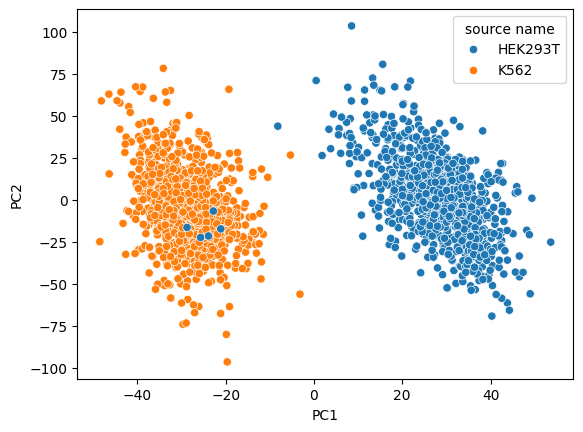

In [42]:
sns.scatterplot(
    adata_precursors.obsm['X_GMF_batch'],
    x='PC1',
    y='PC2',
    hue=adata_precursors.obs['source name']
)

<Axes: xlabel='6', ylabel='7'>

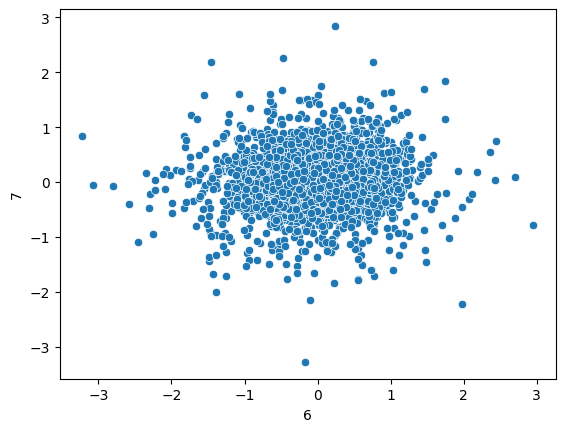

In [ ]:

sns.scatterplot(
    pd.DataFrame(adata_precursors.layers['log2_batch']).T,
    x=6,
    y=7,
)

HEK293T: 796 reference proteins
K562: 800 reference proteins


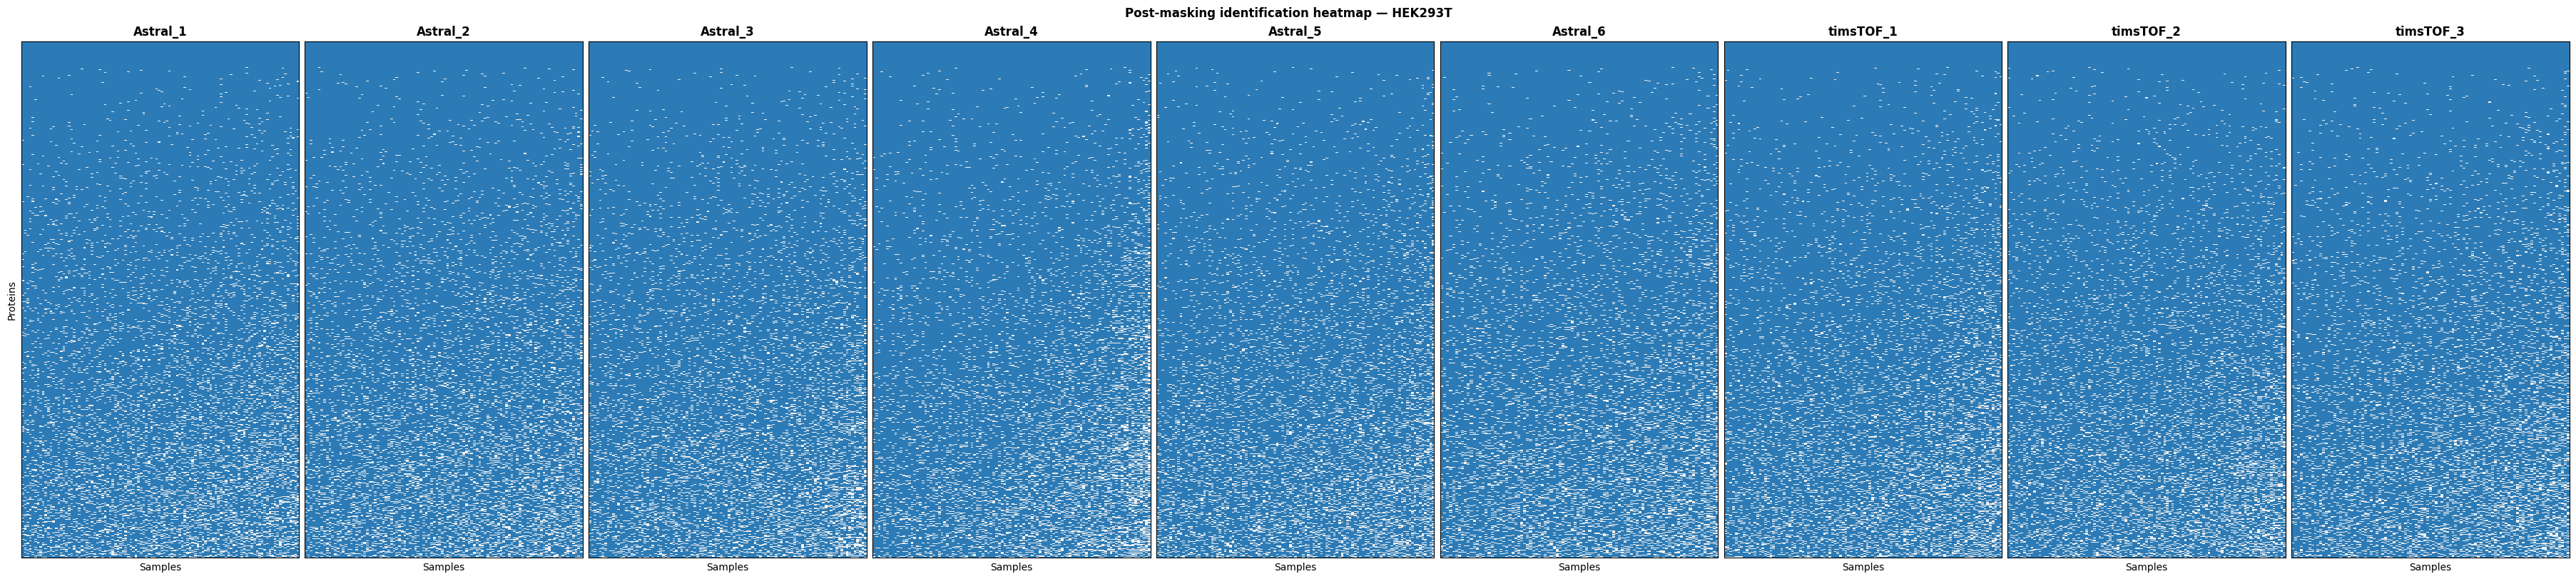

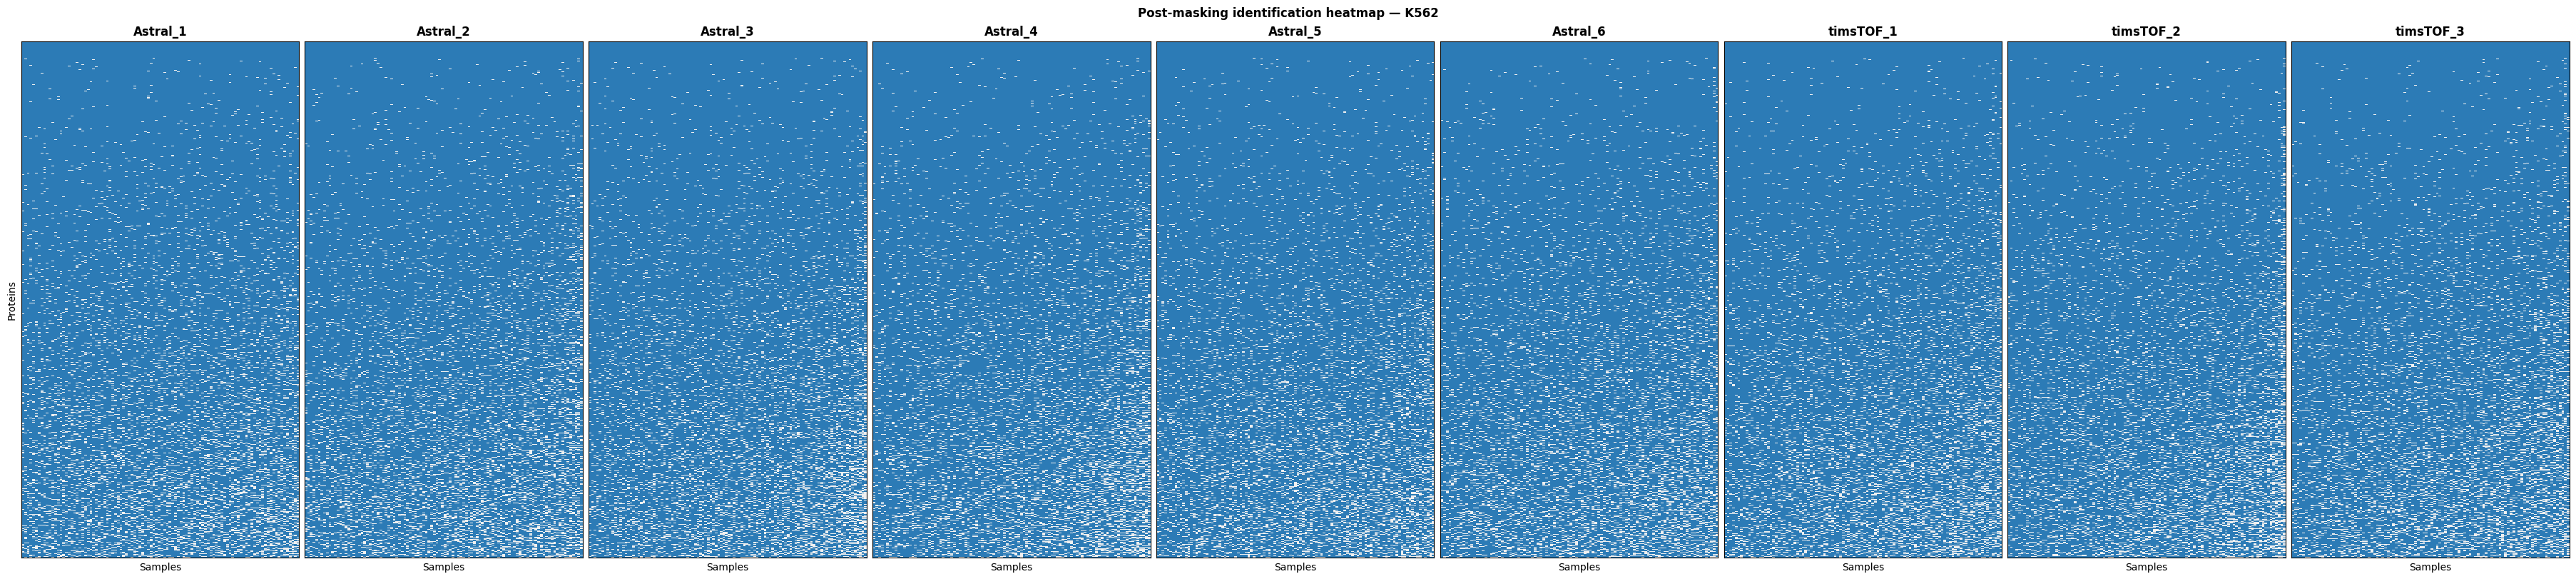

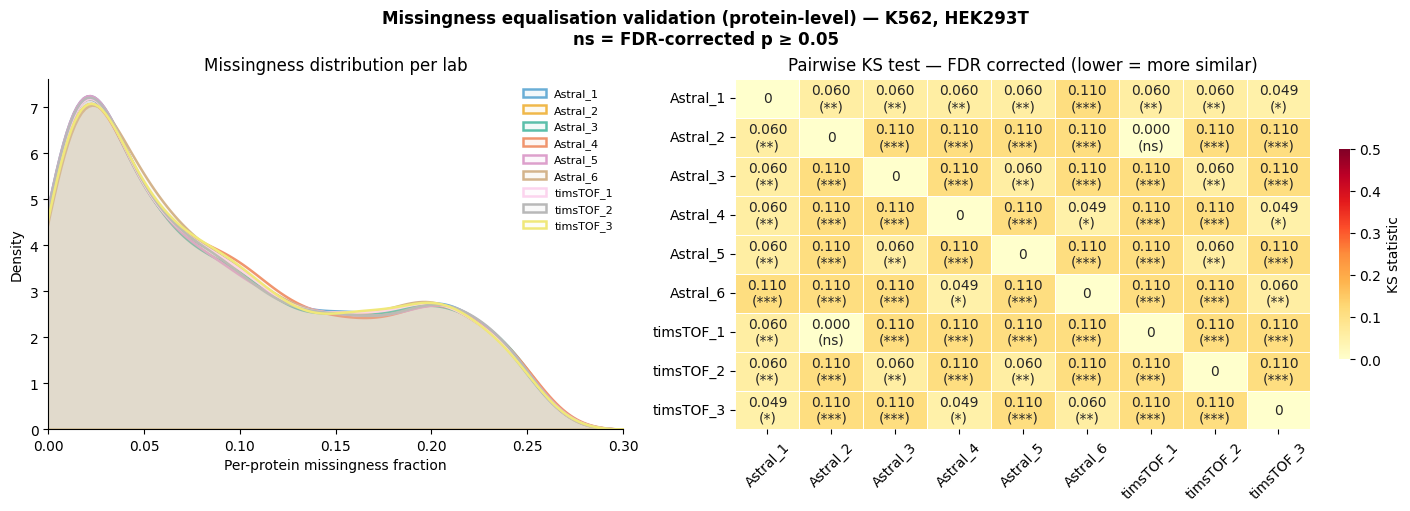

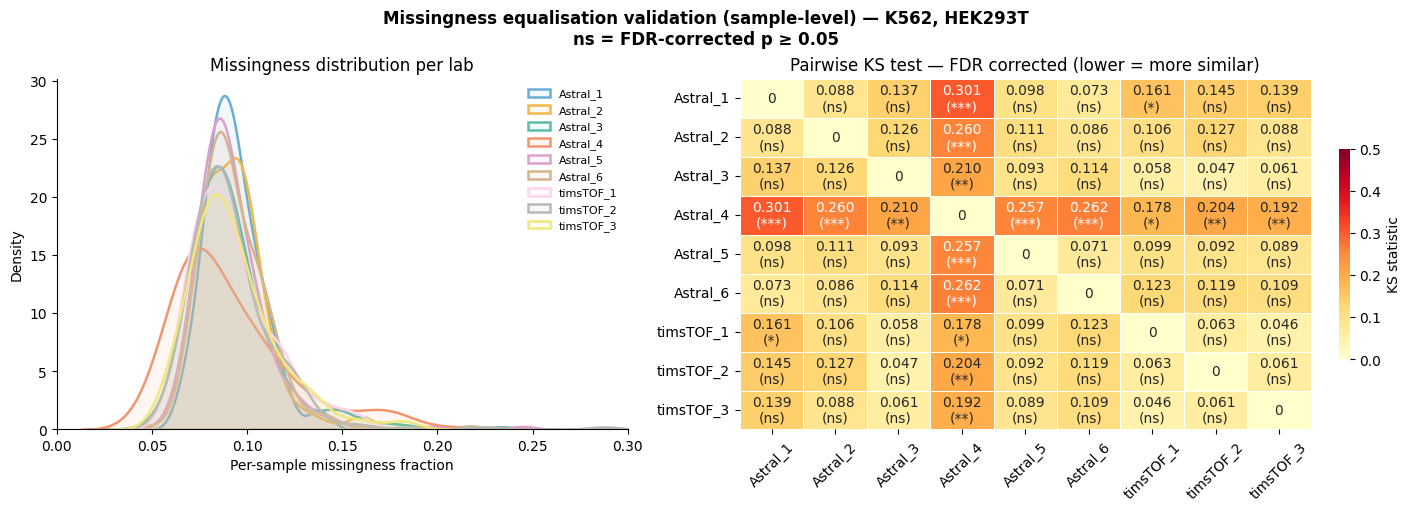

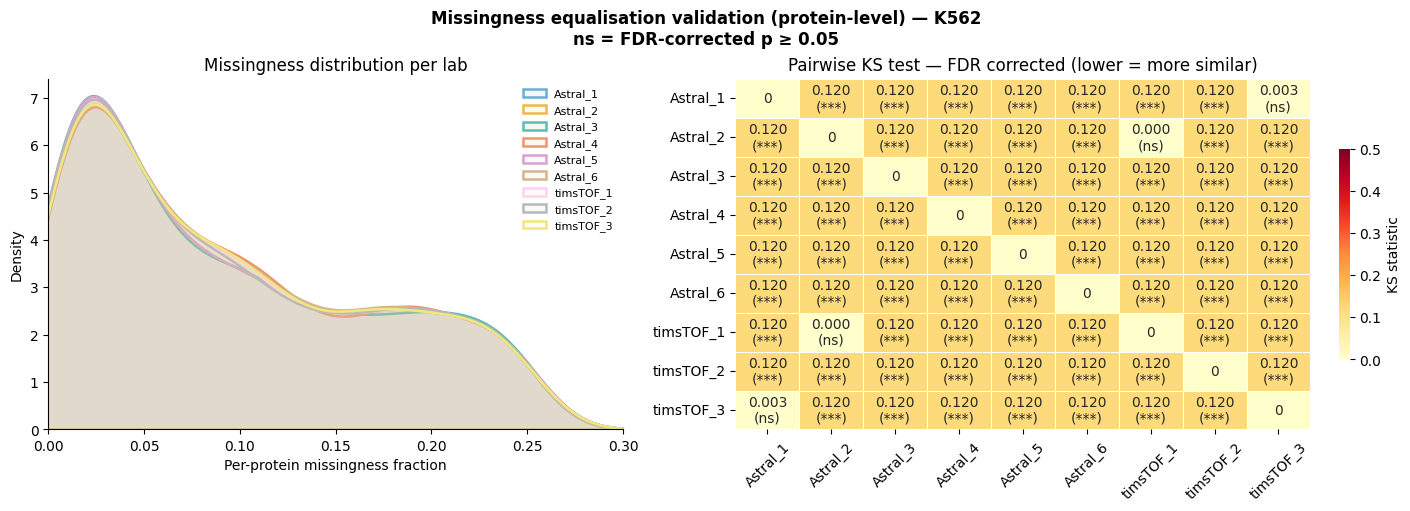

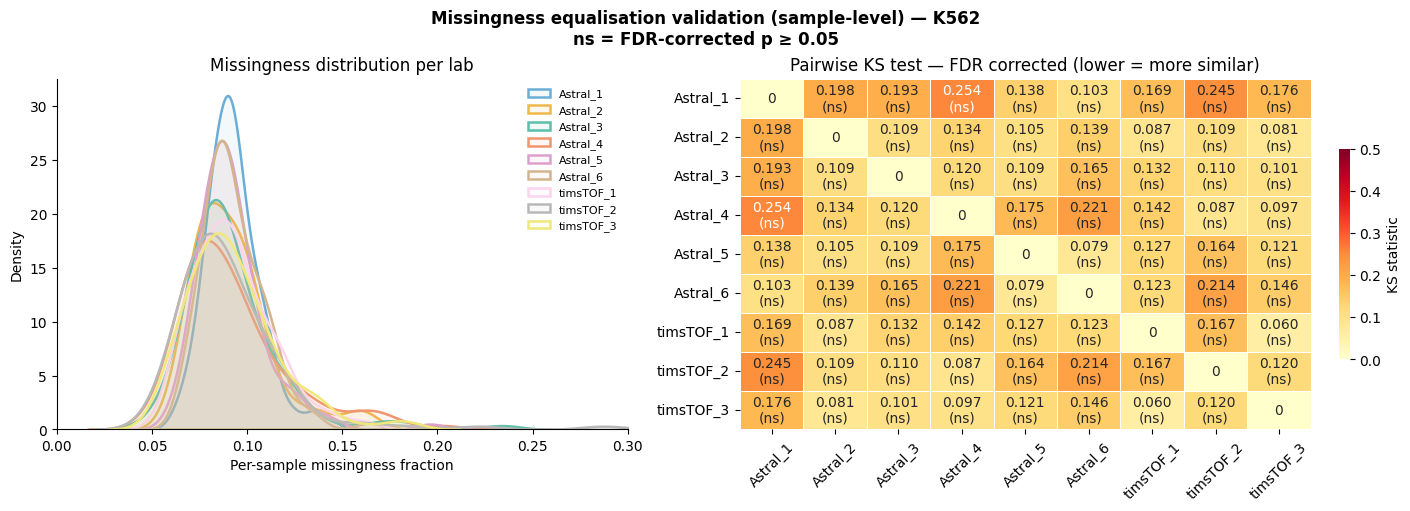

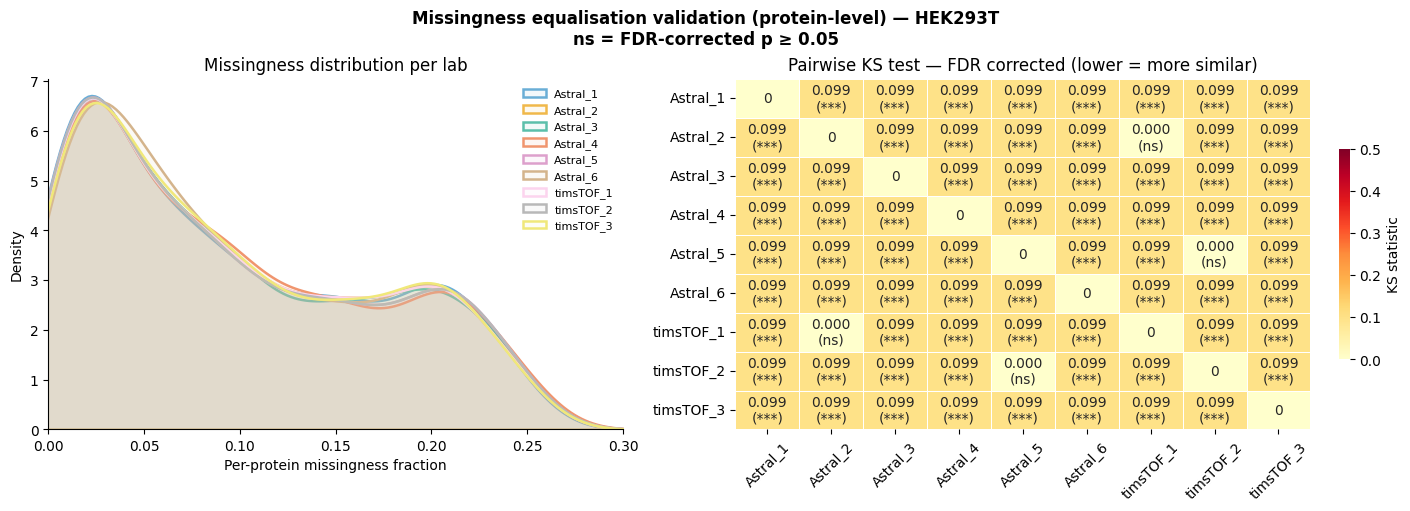

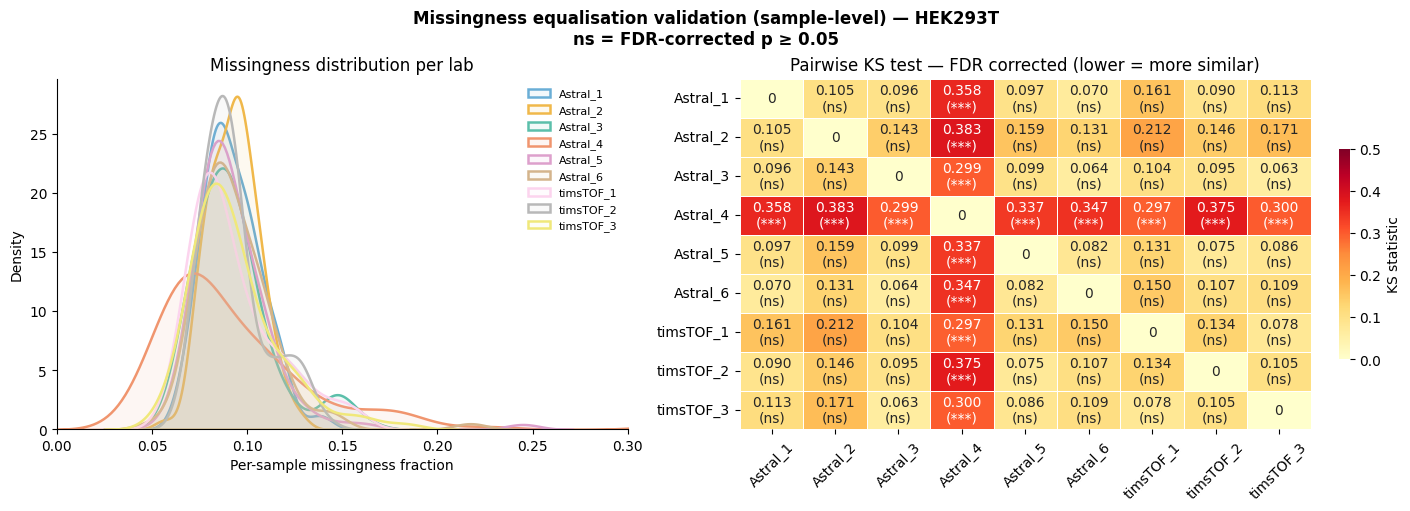

In [21]:
conditions = ['HEK293T', 'K562']

masked_dict, stats_df = create_reference_set(
    adata_precursors[
        ~adata_precursors.obs['completeness_outlier']
    ],
    layer='log2_batch',
    conditions=conditions,
    min_sample_completeness=0,
    min_protein_completeness=.75
)

for condition in conditions:
    plot_masking_heatmap(
        masked_data=masked_dict,
        condition=condition,
        save_dir=False,
        filename=f'masking_heatmap_{condition}',
        show=True
    )
    
    
for cond_label, cond in {
    'SC': ['K562', 'HEK293T'],
    'K562': ['K562'],
    'HEK293T': ['HEK293T']
}.items():
    ks_results = plot_missingness_distributions(
        masked_dict,
        conditions=cond,
        level='protein',
        save_dir=False,
        filename=f'missingness_distribution_protein_{cond_label}',
        xlim_max=.3,
        show=True
    )
    ks_results = plot_missingness_distributions(
        masked_dict,
        conditions=cond,
        level='sample',
        save_dir=False,
        filename=f'missingness_distribution_sample_{cond_label}',
        xlim_max=.3,
        show=True
    )

In [22]:
correlation_results = compute_pairwise_correlations(
    masked_data=masked_dict,
    conditions=conditions,
    adata=adata_precursors[
        ~adata_precursors.obs['completeness_outlier']
    ],
    min_coobserved=50,
)

HEK293T: 931 samples × 796 proteins → 432,915 pairs


HEK293T: 100%|██████████| 931/931 [02:47<00:00,  5.57it/s]


  Done: 432,915 valid pairs
K562: 933 samples × 800 proteins → 434,778 pairs


K562: 100%|██████████| 933/933 [02:48<00:00,  5.54it/s]


  Done: 434,778 valid pairs


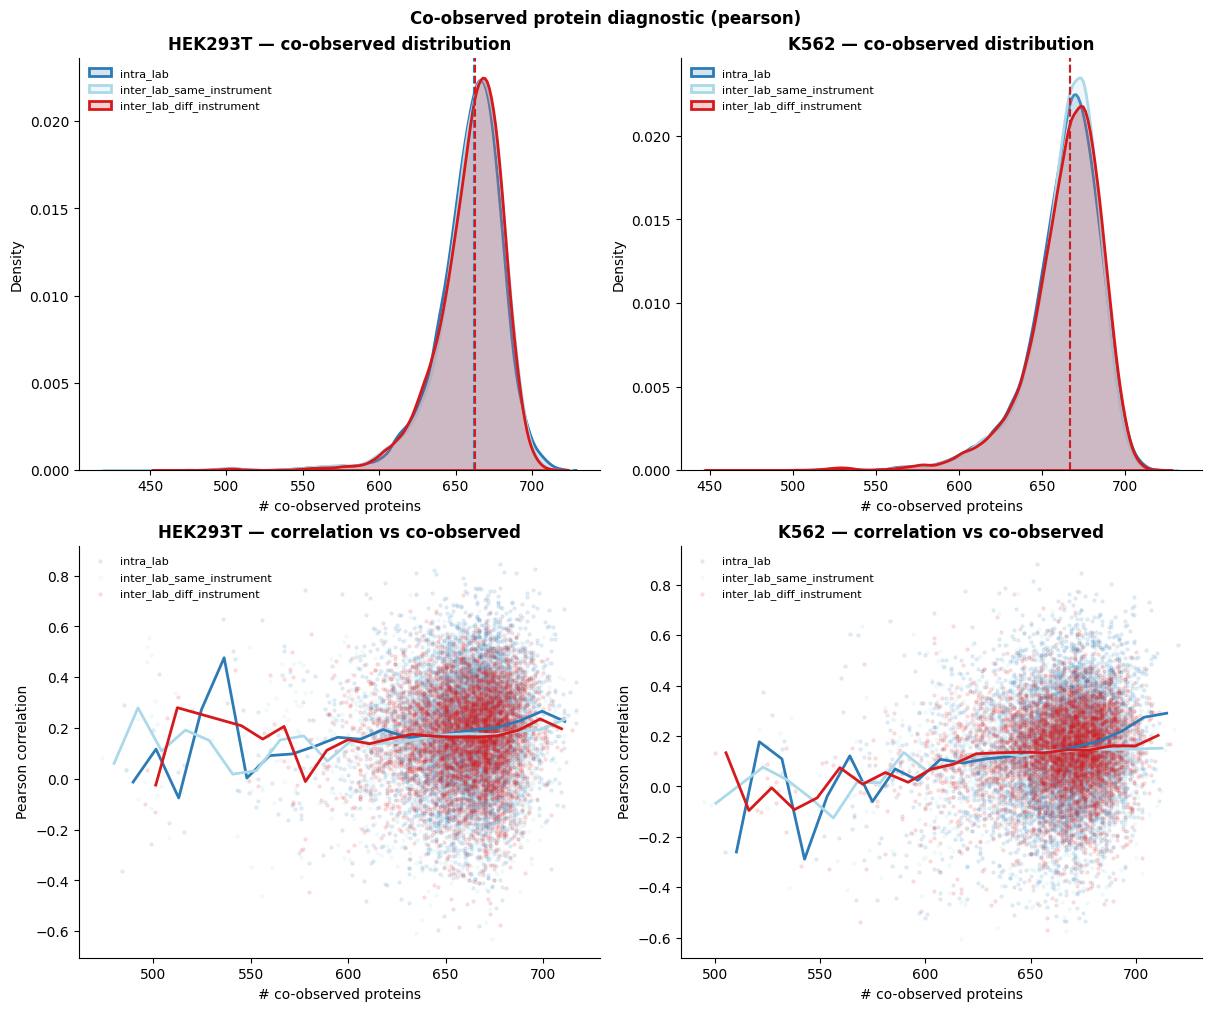

Intralab


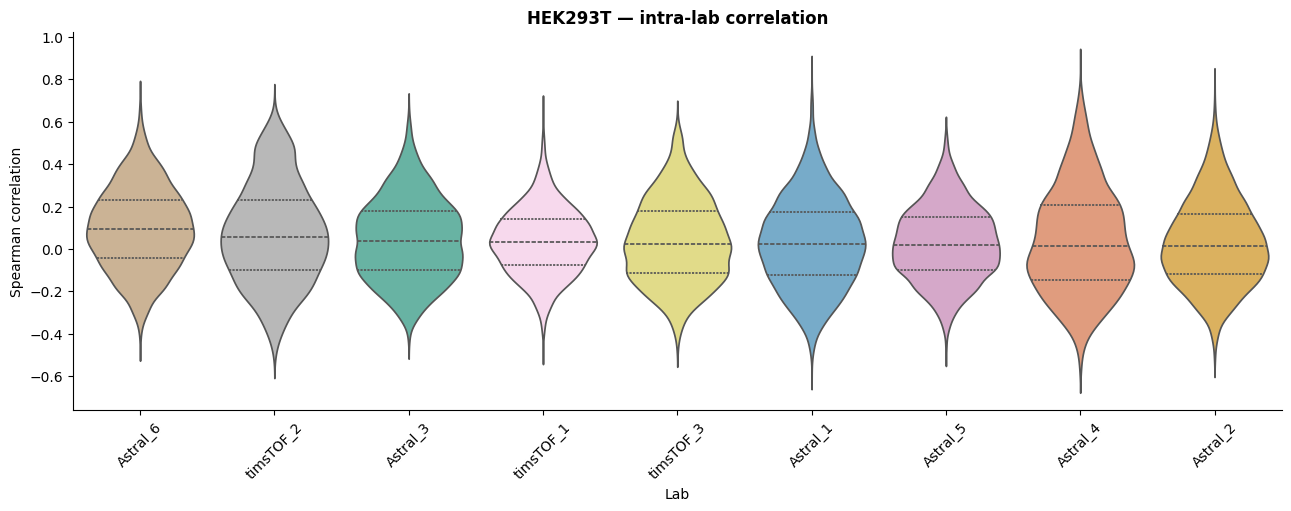

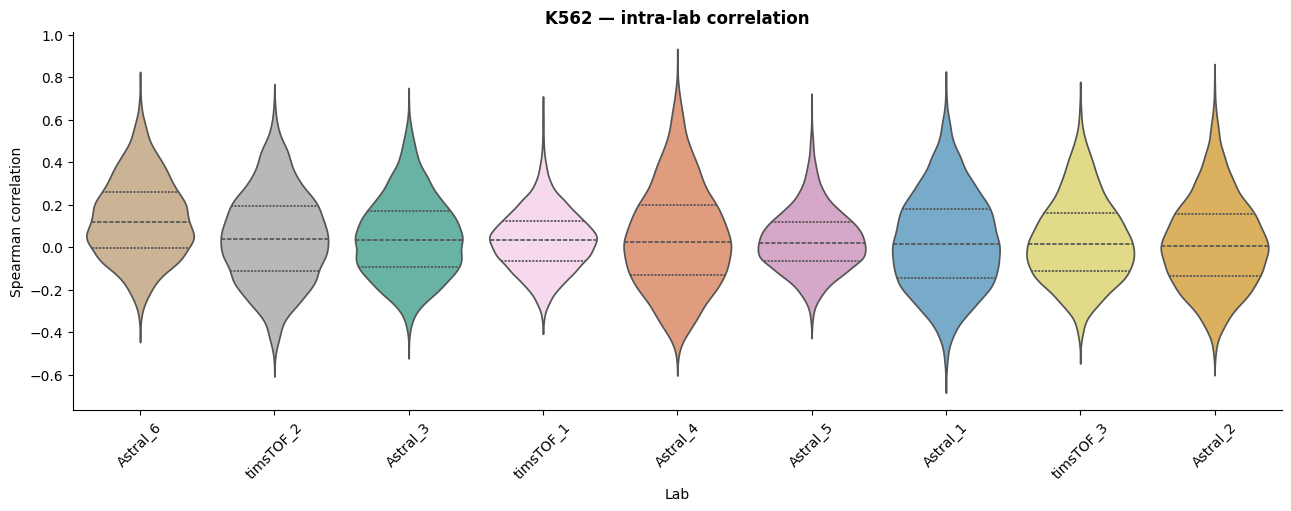

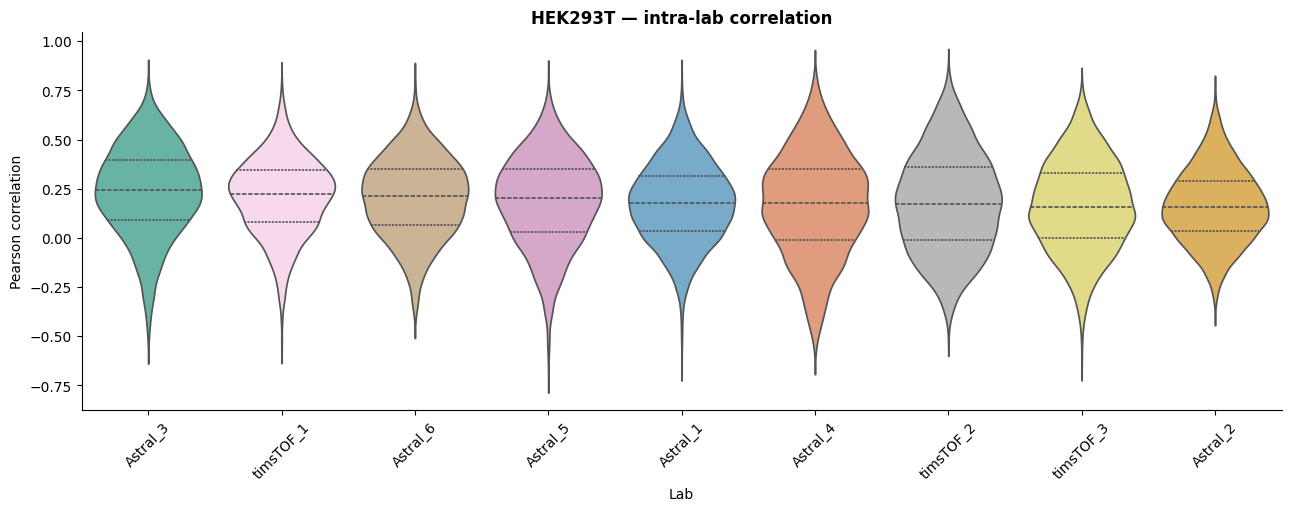

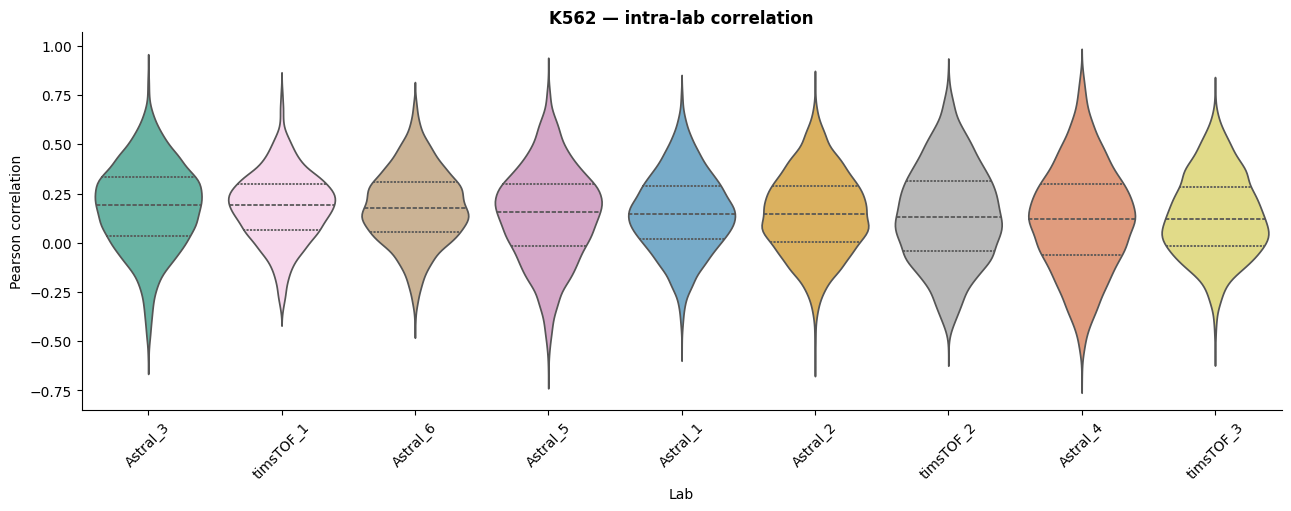

Interlab


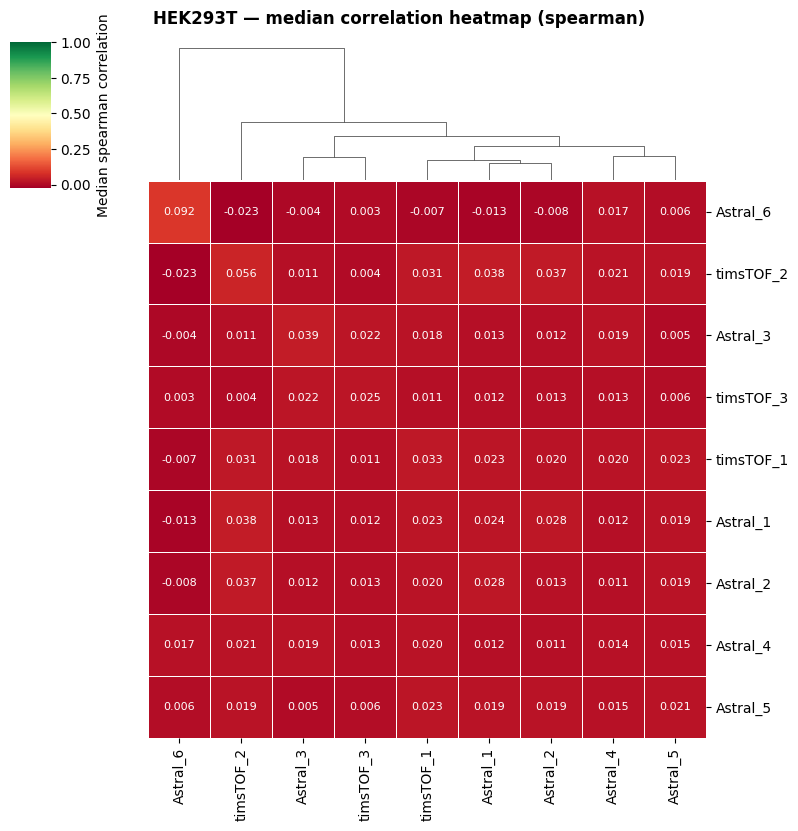

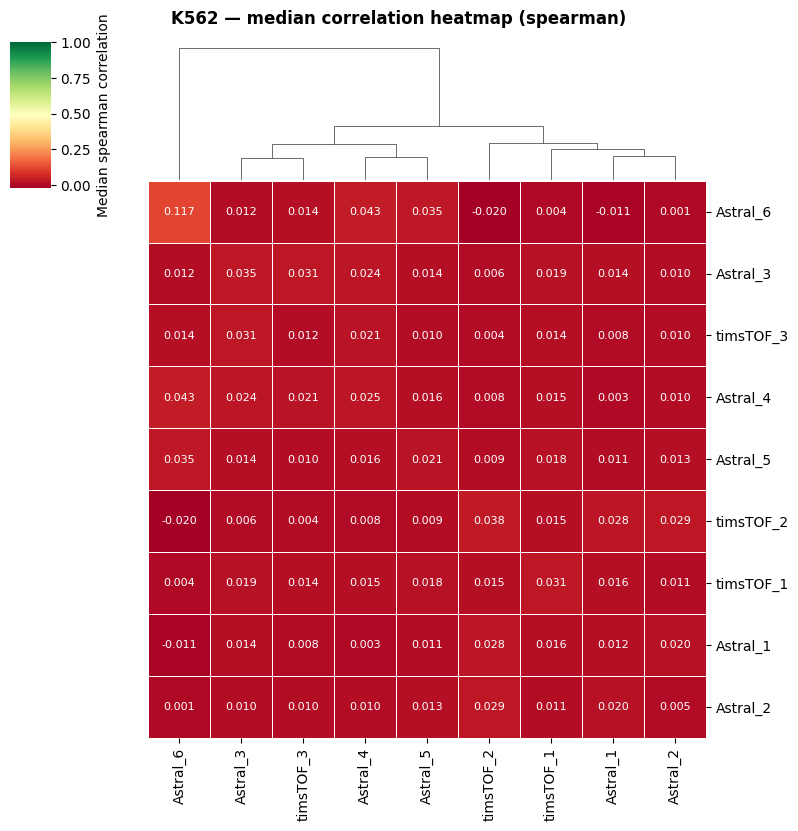

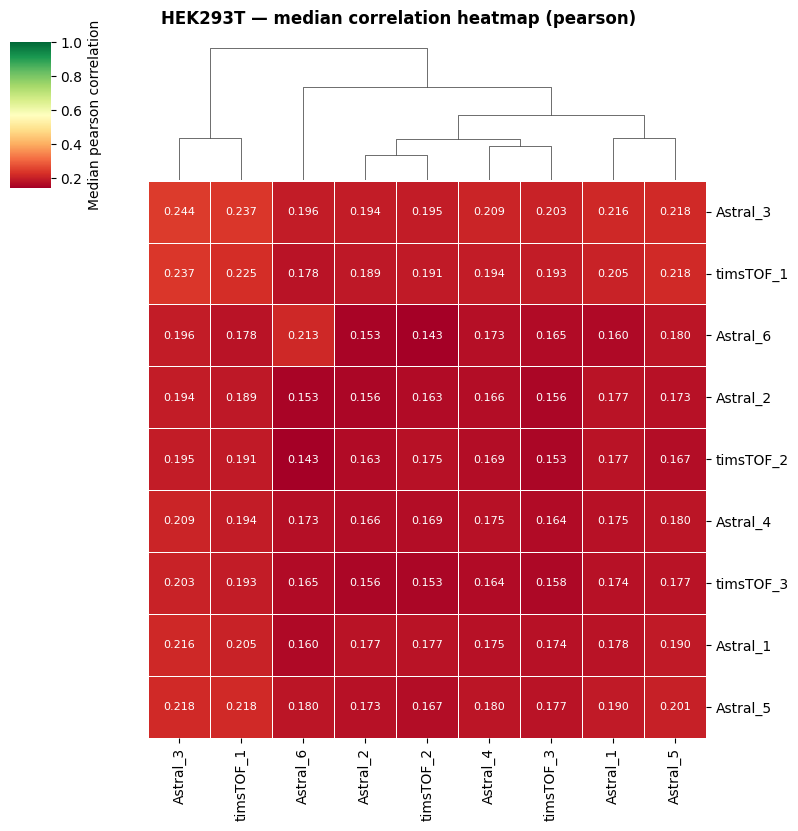

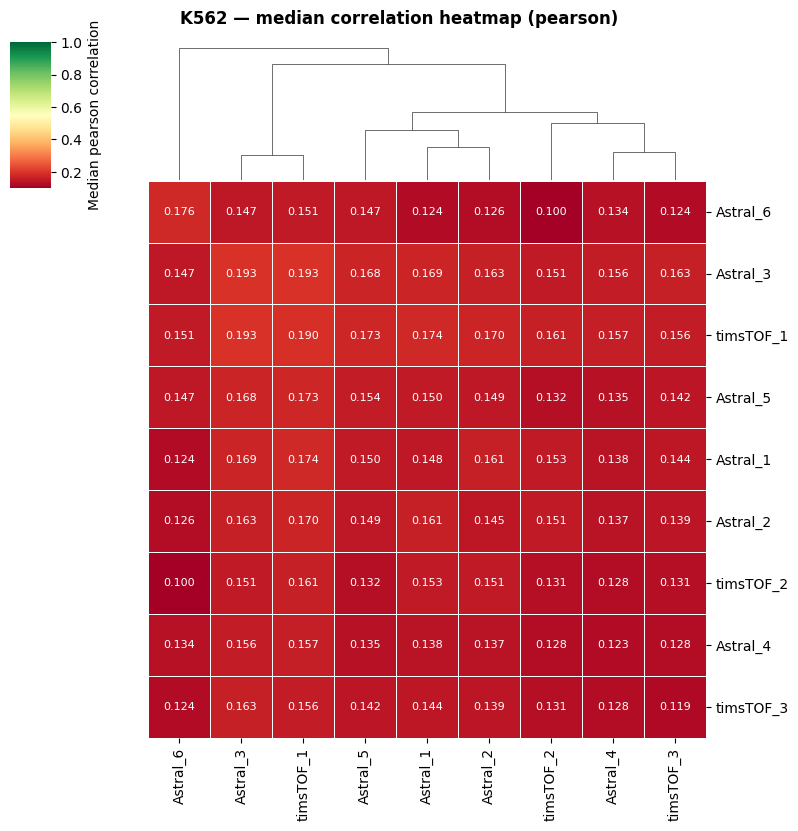

In [23]:
plot_coobserved_diagnostic(
    correlation_results=correlation_results,
    save_dir=False,
    filename='Coobserved_diagnostic_plot',
    show=True
)

print('Intralab')
plot_intralab_correlation(
    correlation_results=correlation_results,
    method='spearman',
    save_dir=False,
    filename_fmt='{cond}_{method}_intralab.png',
    show=True
)

plot_intralab_correlation(
    correlation_results=correlation_results,
    method='pearson',
    save_dir=False,
    filename_fmt='{cond}_{method}_intralab.png',
    show=True
)

print('Interlab')
plot_interlab_correlation_heatmap(
    correlation_results=correlation_results,
    method='spearman',
    save_dir=False,
    filename_fmt='{cond}_{method}_interlab_heatmap.png',
    show=True
)

plot_interlab_correlation_heatmap(
    correlation_results=correlation_results,
    method='pearson',
    save_dir=False,
    filename_fmt='{cond}_{method}_interlab_heatmap.png',
    show=True
)